# Mars Landform Classification using ResNet-50 

this notebook implements transfer learning with pretrained resnet-50 to classify mars surface landforms into 8 categories

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

print(f'pytorch version: {torch.__version__}')
print(f'torchvision version: {torchvision.__version__}')
print(f'cuda available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'cuda device: {torch.cuda.get_device_name(0)}')

pytorch version: 2.10.0+cu128
torchvision version: 0.25.0+cu128
cuda available: True
cuda device: Tesla T4


## 2. Dataset Configuration

In [2]:
BASE = '/kaggle/input/datasets/qasimchaudry/hirise-mars-surface-image-datasets'

dataset_dirs = [
    f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/map-proj-v3_2',
    f'{BASE}/hirise-map-proj-v3/hirise-map-proj-v3/map-proj-v3',
]
labels_file = f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/labels-map-proj_v3_2_train_val_test.txt'

class_names = [
    'other',
    'crater',
    'dark dune',
    'slope streak',
    'bright dune',
    'impact ejecta',
    'swiss cheese',
    'spider'
]
num_classes = len(class_names)

img_size                = 224
batch_size              = 32
num_epochs              = 50
learning_rate           = 0.001
weight_decay            = 1e-4
early_stopping_patience = 15
use_subset              = False
subset_size             = 1000

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'using device: {device}')
if torch.cuda.is_available():
    print(f'gpu: {torch.cuda.get_device_name(0)}')
    print(f'vram: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

model_save_path       = 'best_mars_resnet_model.pth'
inference_config_path = 'resnet_inference_config.json'


using device: cuda
gpu: Tesla T4
vram: 15.6 GB


## 3. Load and Analyze Dataset

In [3]:
# load labels file
df = pd.read_csv(labels_file, sep=' ', header=None, names=['filename', 'class_label', 'split'])
print(f'total samples: {len(df)}')
print(f'\nfirst few rows:')
print(df.head(10))

# check splits
print(f'\nsplit distribution:')
print(df['split'].value_counts())

# check class distribution
print(f'\nclass distribution:')
print(df['class_label'].value_counts().sort_index())

total samples: 67810

first few rows:
                            filename  class_label  split
0       ESP_013049_0950_RED-0067.jpg            7  train
1    ESP_013049_0950_RED-0067-fv.jpg            7  train
2   ESP_013049_0950_RED-0067-brt.jpg            7  train
3   ESP_013049_0950_RED-0067-r90.jpg            7  train
4  ESP_013049_0950_RED-0067-r180.jpg            7  train
5  ESP_013049_0950_RED-0067-r270.jpg            7  train
6    ESP_013049_0950_RED-0067-fh.jpg            7  train
7       ESP_019697_2020_RED-0024.jpg            1  train
8    ESP_019697_2020_RED-0024-fv.jpg            1  train
9   ESP_019697_2020_RED-0024-brt.jpg            1  train

split distribution:
split
train    51058
val      14959
test      1793
Name: count, dtype: int64

class distribution:
class_label
0    52722
1     5857
2      857
3     1603
4     1654
5      777
6     2772
7     1568
Name: count, dtype: int64


In [4]:
# function to find image path
def find_image_path(filename, dataset_dirs):
    # handle missing/NaN filenames
    if pd.isna(filename) or not isinstance(filename, str):
        return None
    for base_dir in dataset_dirs:
        full_path = os.path.join(base_dir, filename)
        if os.path.exists(full_path):
            return full_path
    return None

# verify all images exist
missing_count = 0
valid_indices = []
for idx, row in df.iterrows():
    img_path = find_image_path(row['filename'], dataset_dirs)
    if img_path is None:
        missing_count += 1
    else:
        valid_indices.append(idx)

print(f'missing images: {missing_count}')
print(f'valid images: {len(valid_indices)}')

# filter dataframe to only valid images
df = df.loc[valid_indices].reset_index(drop=True)
print(f'\nfiltered dataset size: {len(df)}')

# check if we have any valid data
if len(df) == 0:
    raise ValueError(f'No valid images found! Check that images exist in these directories: {dataset_dirs}')

missing images: 0
valid images: 67810

filtered dataset size: 67810


## 4. Visualize Class Distribution

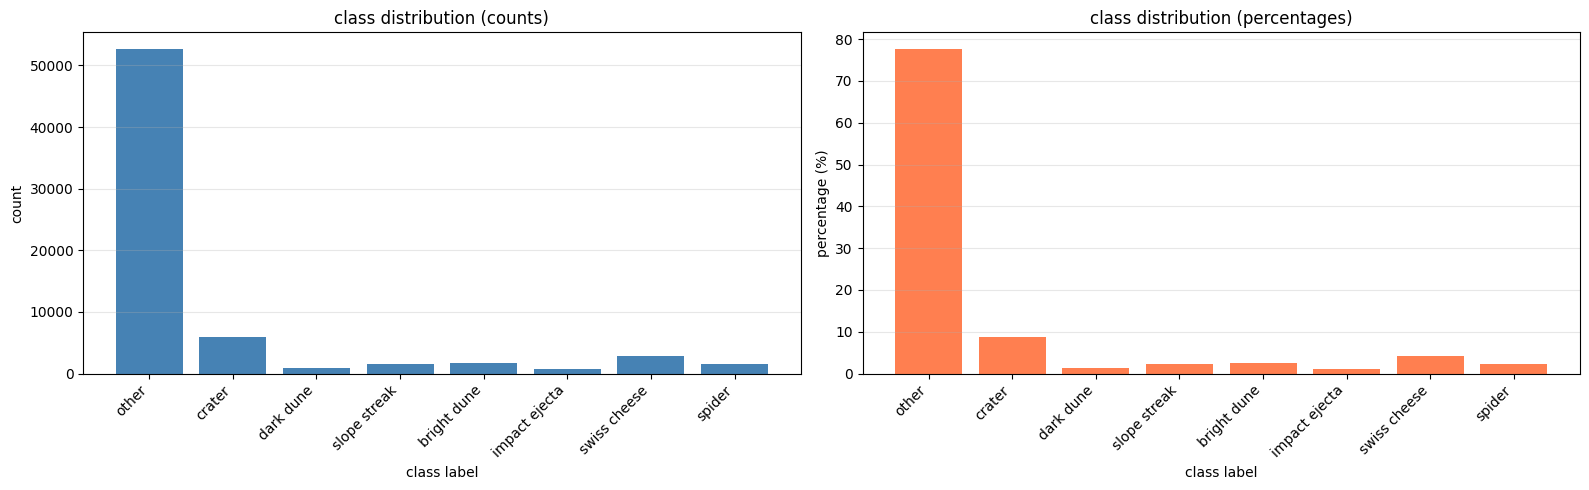

class distribution:
class 0 (other): 52722 samples (77.75%)
class 1 (crater): 5857 samples (8.64%)
class 2 (dark dune): 857 samples (1.26%)
class 3 (slope streak): 1603 samples (2.36%)
class 4 (bright dune): 1654 samples (2.44%)
class 5 (impact ejecta): 777 samples (1.15%)
class 6 (swiss cheese): 2772 samples (4.09%)
class 7 (spider): 1568 samples (2.31%)


In [5]:
# overall class distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# count plot
class_counts = df['class_label'].value_counts().sort_index()
axes[0].bar(range(num_classes), class_counts.values, color='steelblue')
axes[0].set_xlabel('class label')
axes[0].set_ylabel('count')
axes[0].set_title('class distribution (counts)')
axes[0].set_xticks(range(num_classes))
axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].grid(axis='y', alpha=0.3)

# percentage plot
class_percentages = (class_counts / len(df)) * 100
axes[1].bar(range(num_classes), class_percentages.values, color='coral')
axes[1].set_xlabel('class label')
axes[1].set_ylabel('percentage (%)')
axes[1].set_title('class distribution (percentages)')
axes[1].set_xticks(range(num_classes))
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
plt.close('all')

print('class distribution:')

for i in range(num_classes):
    count = class_counts.get(i, 0)
    pct = class_percentages.get(i, 0)
    print(f'class {i} ({class_names[i]}): {count} samples ({pct:.2f}%)')

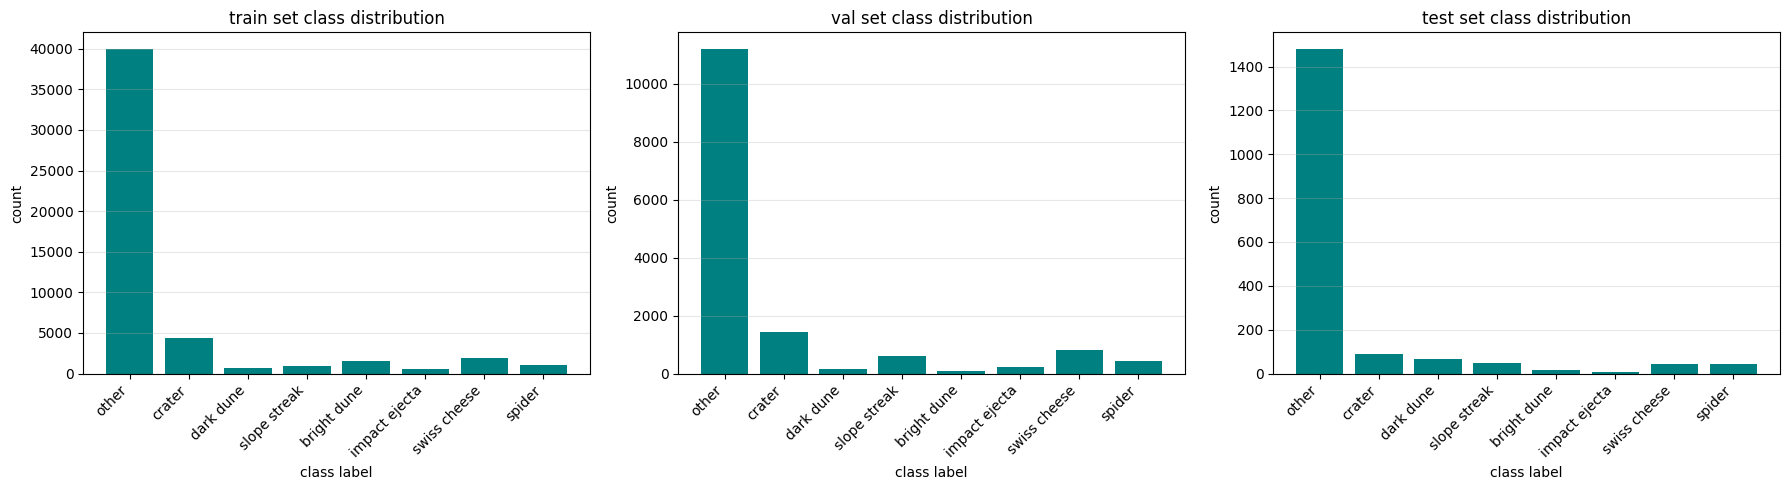

In [6]:
# class distribution by split
split_class_dist = df.groupby(['split', 'class_label']).size().unstack(fill_value=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
splits = ['train', 'val', 'test']

for idx, split in enumerate(splits):
    if split in split_class_dist.index:
        counts = split_class_dist.loc[split]
        axes[idx].bar(range(num_classes), counts.values, color='teal')
        axes[idx].set_xlabel('class label')
        axes[idx].set_ylabel('count')
        axes[idx].set_title(f'{split} set class distribution')
        axes[idx].set_xticks(range(num_classes))
        axes[idx].set_xticklabels(class_names, rotation=45, ha='right')
        axes[idx].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
plt.close('all')

## 5. Calculate Class Weights

In [7]:
# calculate inverse frequency weights from training set
train_df = df[df['split'] == 'train']
train_class_counts = train_df['class_label'].value_counts().sort_index()

# inverse frequency weighting
total_train_samples = len(train_df)
class_weights = []
for i in range(num_classes):
    count = train_class_counts.get(i, 1)  # avoid division by zero
    weight = total_train_samples / (num_classes * count)
    class_weights.append(weight)

class_weights = torch.FloatTensor(class_weights).to(device)

print(f'Class weights calculated and applied')



Class weights calculated and applied


## 6. Define Custom Dataset Class

In [8]:
class MarsLandformDataset(Dataset):
    def __init__(self, dataframe, dataset_dirs, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_dirs = dataset_dirs
        self.transform = transform
    
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        filename = row['filename']
        label = row['class_label']
        
        # find image path
        img_path = find_image_path(filename, self.dataset_dirs)
        
        # load image
        image = Image.open(img_path).convert('RGB')
        
        # apply transforms
        if self.transform:
            image = self.transform(image)
        
        return image, label

print('custom dataset class defined')

custom dataset class defined


## 7. Define Data Transformations

In [9]:
# ImageNet normalization statistics
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# training transforms with data augmentation
train_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# validation and test transforms
val_test_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

print('Data transformations defined')

Data transformations defined


## 8. Create DataLoaders

In [10]:
train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df   = df[df['split'] == 'val'].reset_index(drop=True)
test_df  = df[df['split'] == 'test'].reset_index(drop=True)

if use_subset:
    train_df = train_df.head(subset_size)
    val_df   = val_df.head(subset_size // 2)
    test_df  = test_df.head(subset_size // 2)
    print(f'using subset: {subset_size} train samples')

print(f'train samples:      {len(train_df)}')
print(f'validation samples: {len(val_df)}')
print(f'test samples:       {len(test_df)}')

train_dataset = MarsLandformDataset(train_df, dataset_dirs, transform=train_transforms)
val_dataset   = MarsLandformDataset(val_df,   dataset_dirs, transform=val_test_transforms)
test_dataset  = MarsLandformDataset(test_df,  dataset_dirs, transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=2, pin_memory=True, persistent_workers=False)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=False)

print(f'train batches:      {len(train_loader)}')
print(f'validation batches: {len(val_loader)}')
print(f'test batches:       {len(test_loader)}')


train samples:      51058
validation samples: 14959
test samples:       1793
train batches:      1596
validation batches: 468
test batches:       57


## 9. Visualize Sample Images

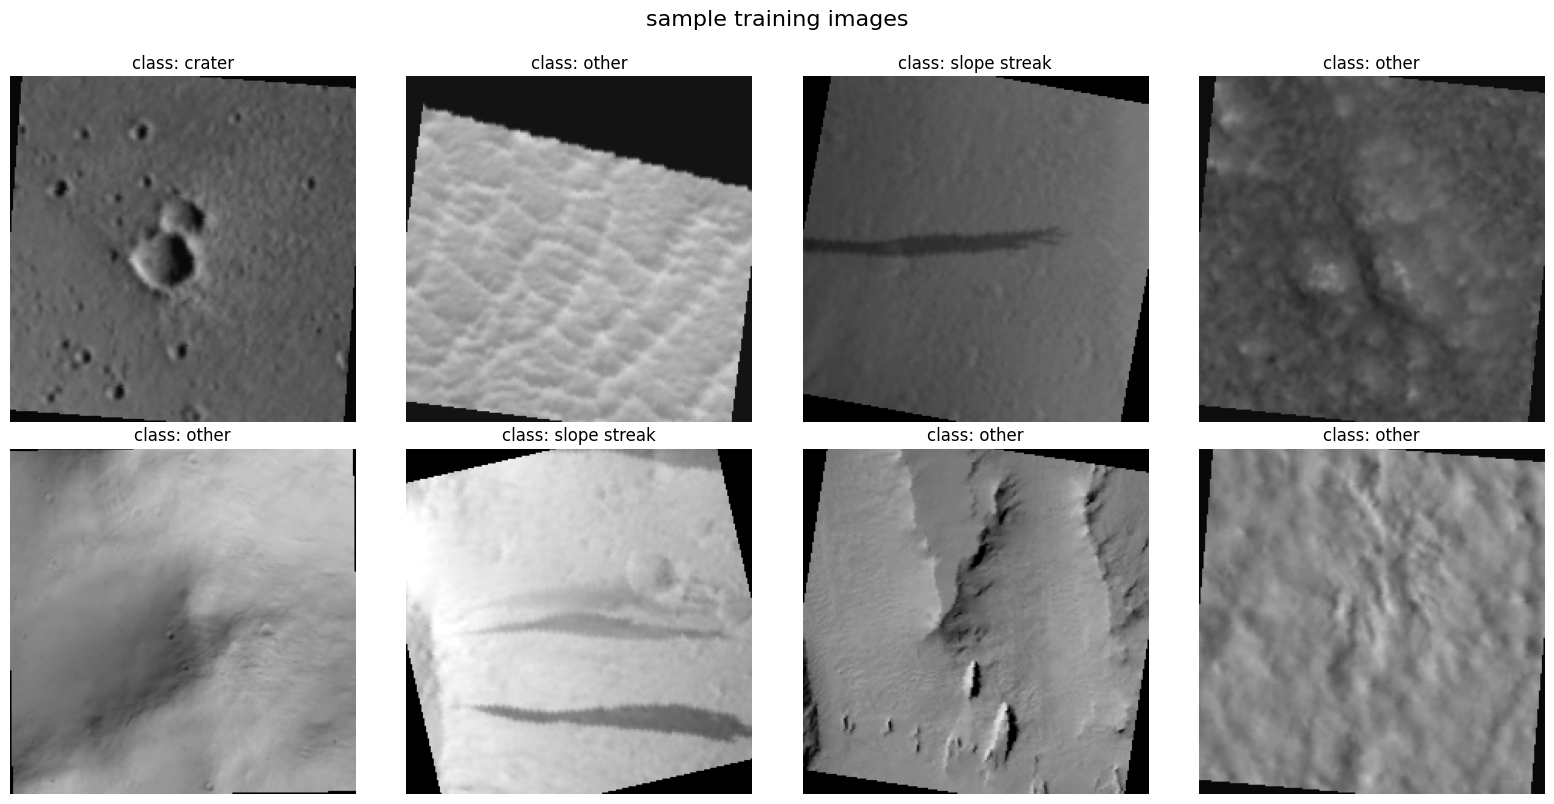

In [11]:
# function to denormalize images for visualization
def denormalize_image(tensor, mean, std):
    tensor = tensor.clone()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)

# visualize sample training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i in range(8):
    img = denormalize_image(images[i], imagenet_mean, imagenet_std)
    img = img.numpy().transpose((1, 2, 0))
    
    axes[i].imshow(img)
    axes[i].set_title(f'class: {class_names[labels[i]]}')
    axes[i].axis('off')

plt.suptitle('sample training images', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()
plt.close('all')

## 10. Load Pretrained ResNet-50 and Modify Final Layer

In [12]:
resnet_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
print('loaded pretrained resnet-50 model')

num_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_features, num_classes)
print(f'modified final layer: {resnet_model.fc}')
print(f'input features: {num_features}, output classes: {num_classes}')

# single gpu only on kaggle — dataparallel causes memory duplication overhead
resnet_model = resnet_model.to(device)
print(f'model moved to {device}')


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 167MB/s]


loaded pretrained resnet-50 model
modified final layer: Linear(in_features=2048, out_features=8, bias=True)
input features: 2048, output classes: 8
model moved to cuda


## 11. Initialize Loss Function and Optimizer

In [13]:
# weighted cross entropy loss
criterion = nn.CrossEntropyLoss(weight=class_weights)
print('loss function: weighted cross entropy')
print(f'class weights applied: {class_weights.cpu().numpy()}')

loss function: weighted cross entropy
class weights applied: [ 0.1594805  1.4729402  9.910326   6.8041043  4.088565  11.840909
  3.3275547  5.77057  ]


## 12. Define Training and Validation Functions

In [14]:
from torch.cuda.amp import autocast, GradScaler

scaler = GradScaler()


def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total   = 0

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        with autocast():
            outputs = model(images)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted  = torch.max(outputs, 1)
        total   += labels.size(0)
        correct += (predicted == labels).sum().item()

        del images, labels, outputs, loss

    return running_loss / total, correct / total


def validate_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total   = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = model(images)
                loss    = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted  = torch.max(outputs, 1)
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()

            del images, labels, outputs, loss

    return running_loss / total, correct / total


print('training and validation functions defined (mixed precision)')


training and validation functions defined (mixed precision)


/tmp/ipykernel_23/3164343622.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


## 13. Train the Model - Strategy 1 (Frozen Backbone)

In [15]:
import gc
import time

print('training: frozen backbone, training only the final fc layer')

for param in resnet_model.parameters():
    param.requires_grad = False

for param in resnet_model.fc.parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
total_params     = sum(p.numel() for p in resnet_model.parameters())
print(f'trainable parameters: {trainable_params:,} / {total_params:,}')
print(f'percentage trainable: {100 * trainable_params / total_params:.2f}%')

optimizer = optim.Adam(filter(lambda p: p.requires_grad, resnet_model.parameters()),
                       lr=learning_rate, weight_decay=weight_decay)
print(f'optimizer: adam, lr={learning_rate}, weight_decay={weight_decay}')

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

best_val_acc     = 0.0
best_val_loss    = float('inf')
patience_counter = 0
training_start   = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()
    print(f'epoch {epoch+1}/{num_epochs}')

    train_loss, train_acc = train_epoch(resnet_model, train_loader, criterion, optimizer, device)
    val_loss, val_acc     = validate_epoch(resnet_model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    epoch_time = time.time() - epoch_start
    print(f'train loss: {train_loss:.4f}, train acc: {train_acc:.4f}')
    print(f'val loss:   {val_loss:.4f},   val acc:   {val_acc:.4f}')
    print(f'epoch time: {epoch_time:.1f}s')

    if val_acc > best_val_acc:
        best_val_acc     = val_acc
        best_val_loss    = val_loss
        patience_counter = 0
        torch.save(resnet_model.state_dict(), model_save_path)
        print(f'  -> best model saved with val_acc: {val_acc:.4f}')
    else:
        patience_counter += 1
        print(f'  -> no improvement ({patience_counter}/{early_stopping_patience})')

    gc.collect()
    torch.cuda.empty_cache()

    if patience_counter >= early_stopping_patience:
        print(f'early stopping triggered after {epoch+1} epochs')
        break

total_time = time.time() - training_start
print(f'training completed in {total_time/60:.1f} minutes')
print(f'best validation accuracy: {best_val_acc:.4f}')
print(f'best validation loss:     {best_val_loss:.4f}')

resnet_model.load_state_dict(torch.load(model_save_path, weights_only=True))
print('best weights reloaded')


training: frozen backbone, training only the final fc layer
trainable parameters: 16,392 / 23,524,424
percentage trainable: 0.07%
optimizer: adam, lr=0.001, weight_decay=0.0001
epoch 1/50


/tmp/ipykernel_23/3164343622.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_23/3164343622.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


train loss: 0.6591, train acc: 0.6970
val loss:   1.0225,   val acc:   0.6434
epoch time: 457.1s
  -> best model saved with val_acc: 0.6434
epoch 2/50
train loss: 0.4311, train acc: 0.7503
val loss:   0.9869,   val acc:   0.7376
epoch time: 269.8s
  -> best model saved with val_acc: 0.7376
epoch 3/50
train loss: 0.3952, train acc: 0.7683
val loss:   1.0432,   val acc:   0.6610
epoch time: 272.4s
  -> no improvement (1/15)
epoch 4/50
train loss: 0.3750, train acc: 0.7706
val loss:   0.9178,   val acc:   0.7386
epoch time: 266.3s
  -> best model saved with val_acc: 0.7386
epoch 5/50
train loss: 0.3699, train acc: 0.7747
val loss:   0.9190,   val acc:   0.7726
epoch time: 265.2s
  -> best model saved with val_acc: 0.7726
epoch 6/50
train loss: 0.3429, train acc: 0.7795
val loss:   0.8444,   val acc:   0.8137
epoch time: 267.2s
  -> best model saved with val_acc: 0.8137
epoch 7/50
train loss: 0.3507, train acc: 0.7829
val loss:   0.8872,   val acc:   0.7778
epoch time: 270.9s
  -> no impro

In [16]:
import json

inference_config = {
    'class_names': class_names,
    'image_size': img_size,
    'mean': imagenet_mean,
    'std': imagenet_std,
    'num_classes': num_classes
}
with open(inference_config_path, 'w') as f:
    json.dump(inference_config, f, indent=2)

print(f'inference config saved to {inference_config_path}')


inference config saved to resnet_inference_config.json


## 14. Plot Training History

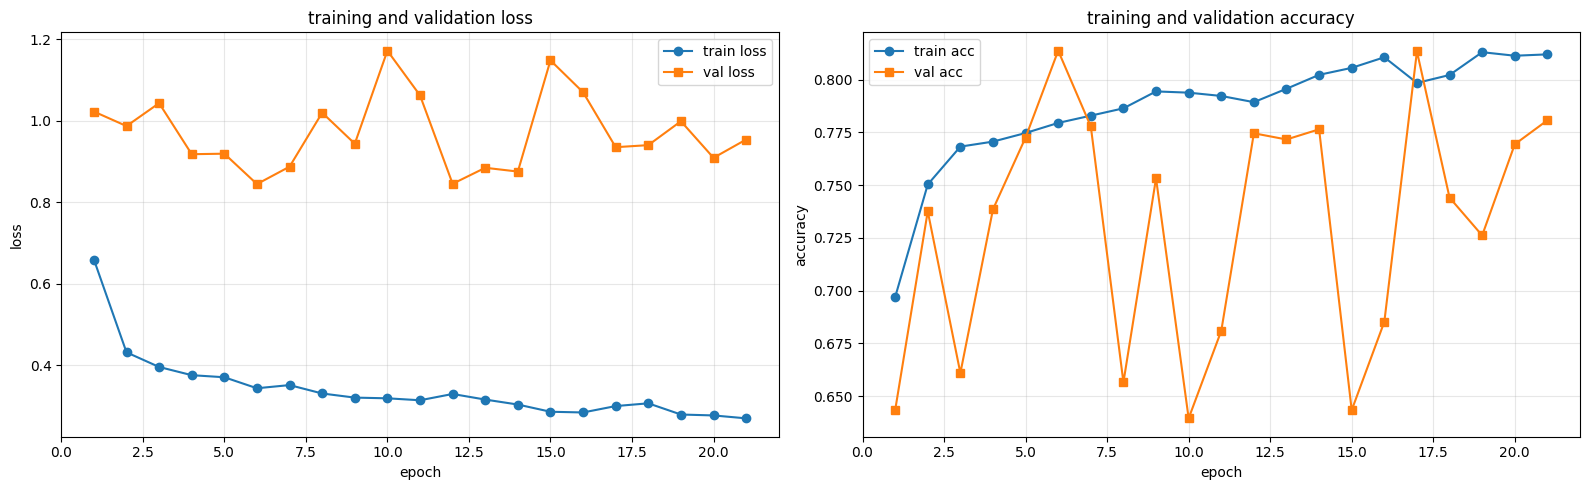

In [17]:
total_epochs = len(history['train_loss'])

# plot training curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# loss plot
axes[0].plot(range(1, total_epochs + 1), history['train_loss'], label='train loss', marker='o')
axes[0].plot(range(1, total_epochs + 1), history['val_loss'], label='val loss', marker='s')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].set_title('training and validation loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# accuracy plot
axes[1].plot(range(1, total_epochs + 1), history['train_acc'], label='train acc', marker='o')
axes[1].plot(range(1, total_epochs + 1), history['val_acc'], label='val acc', marker='s')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy')
axes[1].set_title('training and validation accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
plt.close('all')

## 15. Load Best Model

In [18]:
resnet_model.load_state_dict(torch.load(model_save_path, weights_only=True))
resnet_model.eval()
eval_model = resnet_model
print('best model loaded and set to eval mode')


best model loaded and set to eval mode


## 16. Evaluate on Test Set

In [19]:
all_predictions = []
all_labels      = []

eval_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with autocast():
            outputs = eval_model(images)

        _, predicted = torch.max(outputs, 1)
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

        del images, outputs

all_predictions = np.array(all_predictions)
all_labels      = np.array(all_labels)

print(f'collected {len(all_predictions)} test predictions')


/tmp/ipykernel_23/4019091315.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


collected 1793 test predictions


## 17. Calculate Overall Metrics

In [20]:
# calculate overall metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print('overall test set metrics:')
print()
print(f'accuracy: {test_accuracy:.4f}')
print(f'precision (weighted): {test_precision:.4f}')
print(f'recall (weighted): {test_recall:.4f}')
print(f'f1-score (weighted): {test_f1:.4f}')

overall test set metrics:

accuracy: 0.8550
precision (weighted): 0.8788
recall (weighted): 0.8550
f1-score (weighted): 0.8621


## 18. Calculate Per-Class Metrics

In [21]:
# calculate per-class metrics
per_class_precision = precision_score(all_labels, all_predictions, average=None, zero_division=0, labels=list(range(num_classes)))
per_class_recall = recall_score(all_labels, all_predictions, average=None, zero_division=0, labels=list(range(num_classes)))
per_class_f1 = f1_score(all_labels, all_predictions, average=None, zero_division=0, labels=list(range(num_classes)))

print('per-class metrics:')
print()
print(f'{"class":<20} {"precision":<12} {"recall":<12} {"f1-score":<12}')

for i in range(num_classes):
    class_name = class_names[i]
    print(f'{class_name:<20} {per_class_precision[i]:<12.4f} {per_class_recall[i]:<12.4f} {per_class_f1[i]:<12.4f}')

per-class metrics:

class                precision    recall       f1-score    
other                0.9377       0.9035       0.9203      
crater               0.7818       0.4831       0.5972      
dark dune            0.7941       0.8182       0.8060      
slope streak         0.4795       0.7143       0.5738      
bright dune          0.4375       0.8750       0.5833      
impact ejecta        0.0741       0.5714       0.1311      
swiss cheese         0.7000       1.0000       0.8235      
spider               0.0870       0.0476       0.0615      


## 19. Generate Confusion Matrix

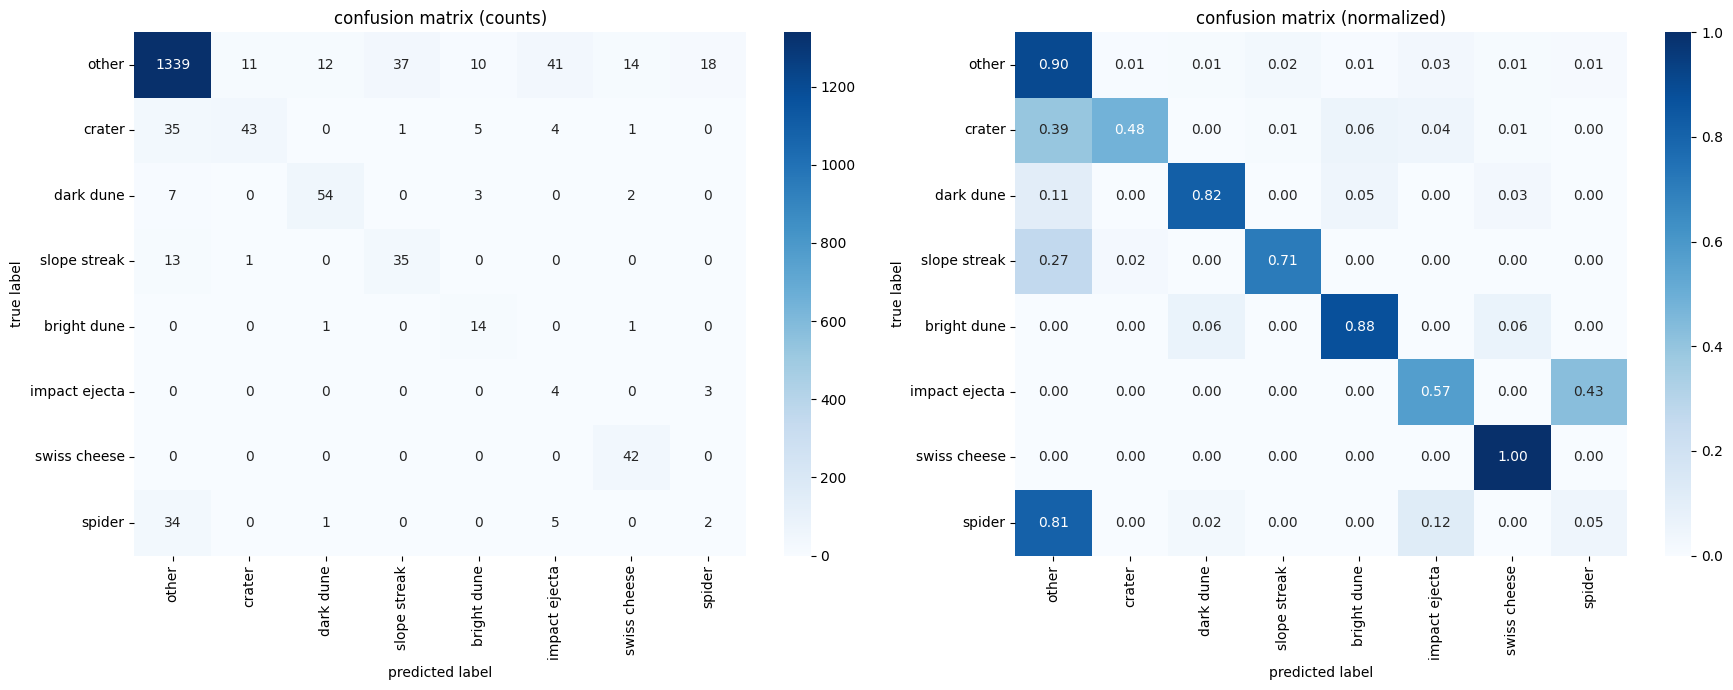

In [22]:
# calculate confusion matrix
cm = confusion_matrix(all_labels, all_predictions)
cm_normalized = confusion_matrix(all_labels, all_predictions, normalize='true')

# plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# raw confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_xlabel('predicted label')
axes[0].set_ylabel('true label')
axes[0].set_title('confusion matrix (counts)')

# normalized confusion matrix
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_xlabel('predicted label')
axes[1].set_ylabel('true label')
axes[1].set_title('confusion matrix (normalized)')

plt.tight_layout()
plt.show()
plt.close('all')

## 20. Visualize Per-Class Performance

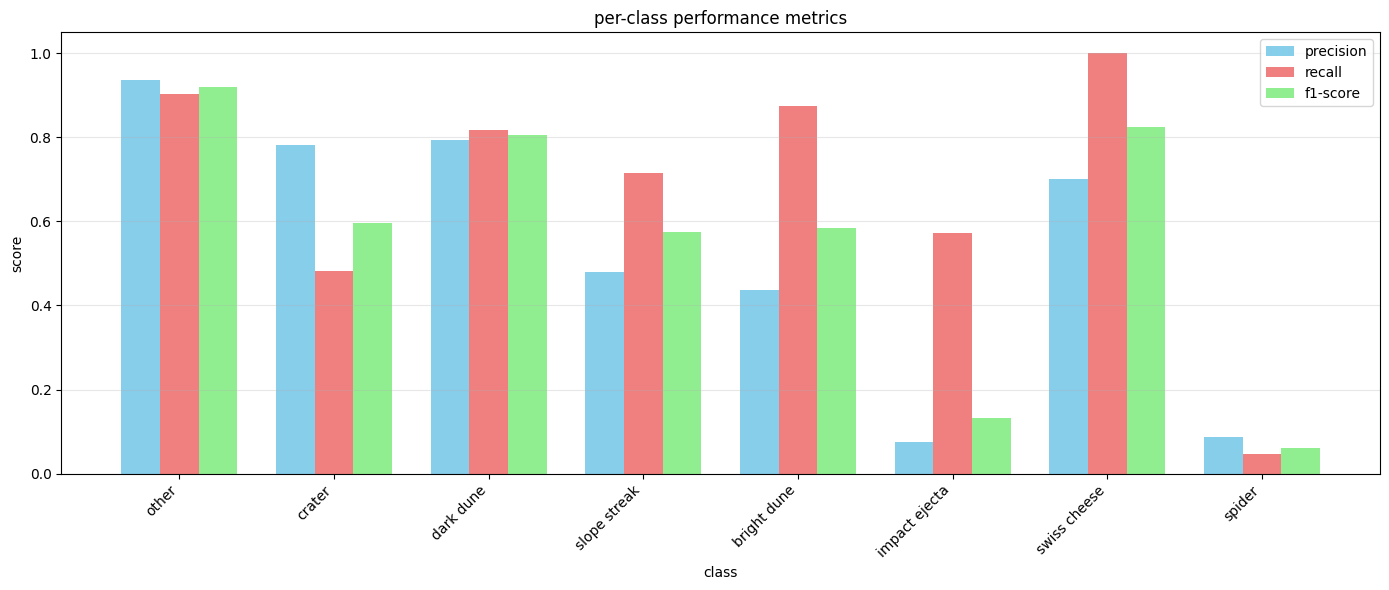

In [23]:
# create per-class performance bar charts
x_pos = np.arange(num_classes)
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x_pos - width, per_class_precision, width, label='precision', color='skyblue')
ax.bar(x_pos, per_class_recall, width, label='recall', color='lightcoral')
ax.bar(x_pos + width, per_class_f1, width, label='f1-score', color='lightgreen')

ax.set_xlabel('class')
ax.set_ylabel('score')
ax.set_title('per-class performance metrics')
ax.set_xticks(x_pos)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
plt.close('all')

## 21. Analyze Class Performance Ranking

In [24]:
# create dataframe for class performance analysis
performance_df = pd.DataFrame({
    'class': class_names,
    'precision': per_class_precision,
    'recall': per_class_recall,
    'f1_score': per_class_f1
})

# sort by f1-score
performance_df = performance_df.sort_values('f1_score', ascending=False).reset_index(drop=True)

print('class performance ranking (sorted by f1-score):')
print()
print(performance_df.to_string(index=False))

# identify best and worst performing classes
best_class = performance_df.iloc[0]
worst_class = performance_df.iloc[-1]

print(f'\nbest performing class: {best_class["class"]} (f1={best_class["f1_score"]:.4f})')
print(f'worst performing class: {worst_class["class"]} (f1={worst_class["f1_score"]:.4f})')

class performance ranking (sorted by f1-score):

        class  precision   recall  f1_score
        other   0.937675 0.903509  0.920275
 swiss cheese   0.700000 1.000000  0.823529
    dark dune   0.794118 0.818182  0.805970
       crater   0.781818 0.483146  0.597222
  bright dune   0.437500 0.875000  0.583333
 slope streak   0.479452 0.714286  0.573770
impact ejecta   0.074074 0.571429  0.131148
       spider   0.086957 0.047619  0.061538

best performing class: other (f1=0.9203)
worst performing class: spider (f1=0.0615)


## 22. Display Sample Predictions

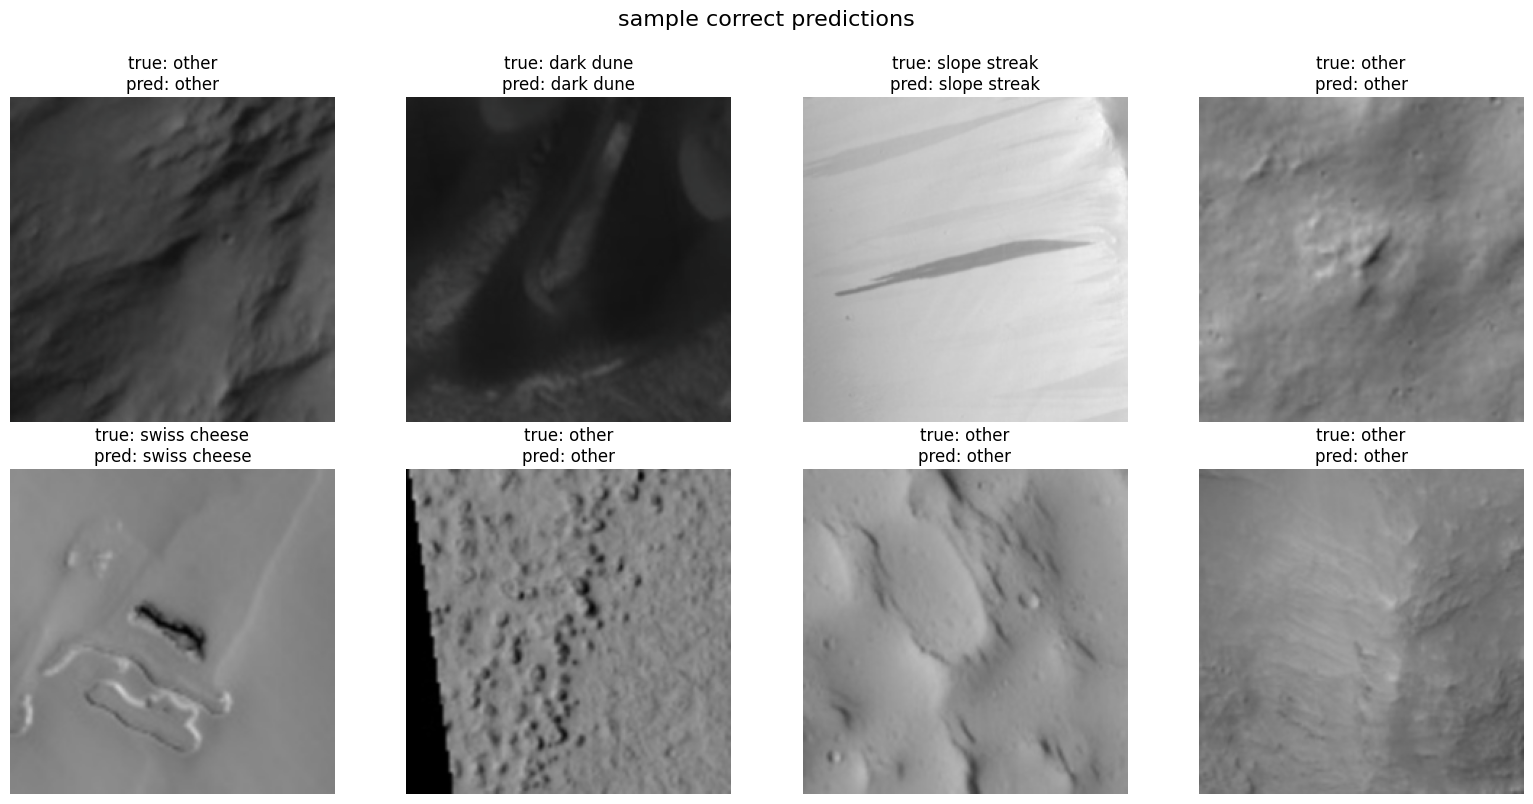

In [25]:
# get sample correct predictions
correct_indices = np.where(all_predictions == all_labels)[0]
sample_correct_indices = np.random.choice(correct_indices, min(8, len(correct_indices)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, sample_idx in enumerate(sample_correct_indices):
    img, label = test_dataset[sample_idx]
    img_denorm = denormalize_image(img, imagenet_mean, imagenet_std)
    img_denorm = img_denorm.numpy().transpose((1, 2, 0))
    
    predicted_label = all_predictions[sample_idx]
    
    axes[idx].imshow(img_denorm)
    axes[idx].set_title(f'true: {class_names[label]}\npred: {class_names[predicted_label]}')
    axes[idx].axis('off')

plt.suptitle('sample correct predictions', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()
plt.close('all')

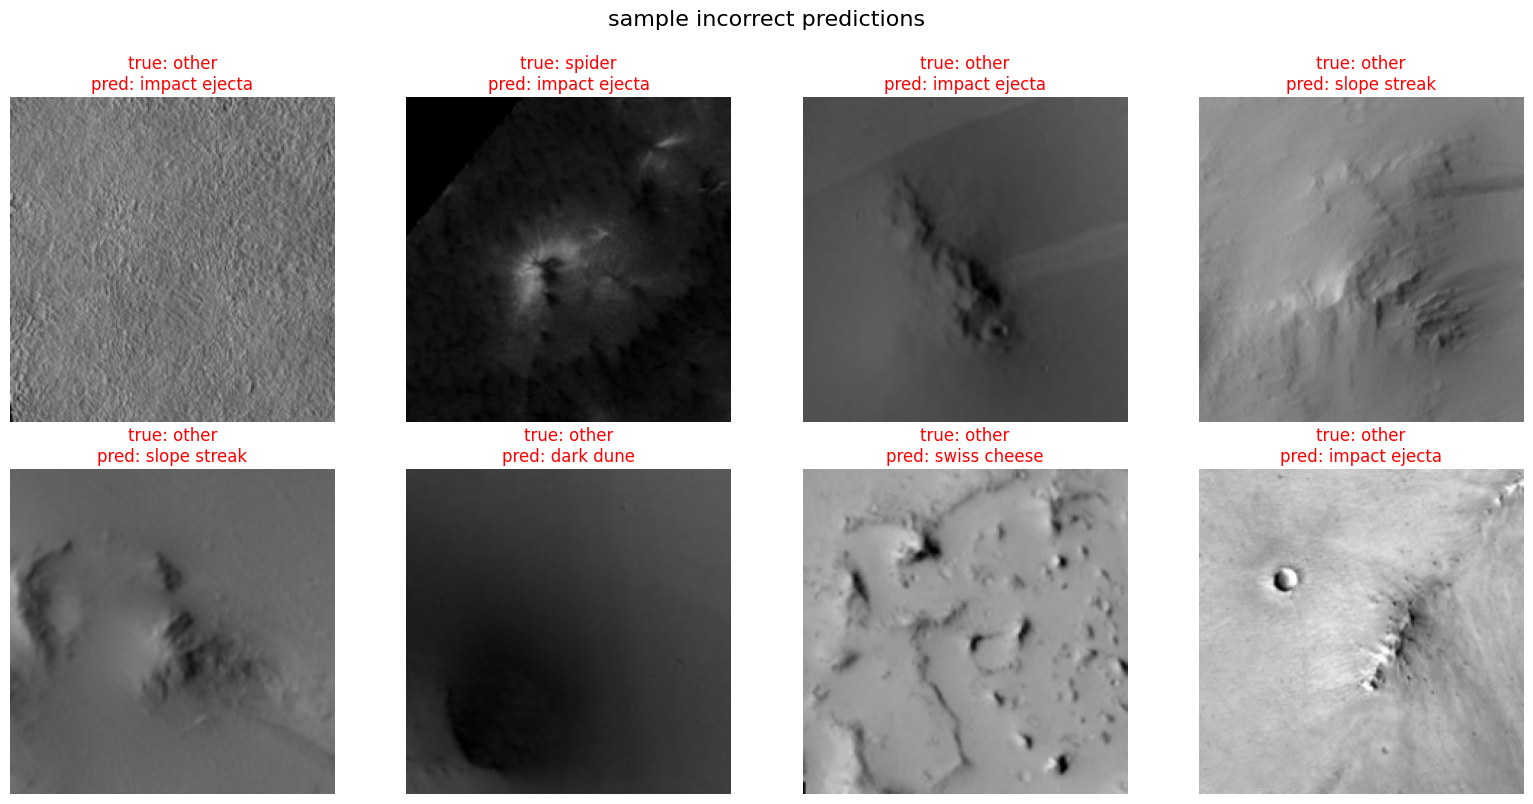

In [26]:
incorrect_indices = np.where(all_predictions != all_labels)[0]

if len(incorrect_indices) > 0:
    sample_incorrect_indices = np.random.choice(
        incorrect_indices,
        min(8, len(incorrect_indices)),
        replace=False
    )
    
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    
    for idx, sample_idx in enumerate(sample_incorrect_indices):
        img, label = test_dataset[sample_idx]
        img_denorm = denormalize_image(img, imagenet_mean, imagenet_std)
        img_denorm = img_denorm.numpy().transpose((1, 2, 0))
        
        predicted_label = all_predictions[sample_idx]
        
        axes[idx].imshow(img_denorm)
        axes[idx].set_title(
            f'true: {class_names[label]}\npred: {class_names[predicted_label]}',
            color='red'
        )
        axes[idx].axis('off')
    
    plt.suptitle('sample incorrect predictions', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()

    plt.close('all')   # ✅ moved inside if

else:
    print('no incorrect predictions found - perfect accuracy')

## 23. Classification Report

In [27]:
# generate detailed classification report
report = classification_report(all_labels, all_predictions, 
                               target_names=class_names, 
                               labels=list(range(num_classes)),
                               zero_division=0)

print('detailed classification report:')
print()
print(report)

detailed classification report:

               precision    recall  f1-score   support

        other       0.94      0.90      0.92      1482
       crater       0.78      0.48      0.60        89
    dark dune       0.79      0.82      0.81        66
 slope streak       0.48      0.71      0.57        49
  bright dune       0.44      0.88      0.58        16
impact ejecta       0.07      0.57      0.13         7
 swiss cheese       0.70      1.00      0.82        42
       spider       0.09      0.05      0.06        42

     accuracy                           0.85      1793
    macro avg       0.54      0.68      0.56      1793
 weighted avg       0.88      0.85      0.86      1793



## 24. Summary and Conclusions

In [28]:
print('Mars Landform Classification with ResNet-50 Transfer Learning - Summary')
print()
print('MODEL ARCHITECTURE:')
print('  Pretrained ResNet-50 from ImageNet')
print('  Modified final FC layer for 8 output classes')
print('  Input size: 224x224 pixels')
print()
print('TRAINING STRATEGY (matched to MobileNet for fair comparison):')
print(f'  Single-stage training: Frozen backbone, train FC layer only')
print(f'  Epochs: {num_epochs}, LR: {learning_rate}, Batch size: {batch_size}')
print(f'  Early stopping patience: {early_stopping_patience} epochs')
print()
print('DATASET:')
print(f'  Total samples: {len(df)}')
print(f'  Train samples: {len(train_df)}')
print(f'  Validation samples: {len(val_df)}')
print(f'  Test samples: {len(test_df)}')
print(f'  Number of classes: {num_classes}')
print()
print('TEST SET PERFORMANCE:')
print(f'  Accuracy: {test_accuracy:.4f}')
print(f'  Precision (weighted): {test_precision:.4f}')
print(f'  Recall (weighted): {test_recall:.4f}')
print(f'  F1-score (weighted): {test_f1:.4f}')
print()
print('KEY OBSERVATIONS:')
print('  Transfer learning with ResNet-50 provides strong baseline performance')
print('  Pretrained ImageNet weights offer better starting point than random initialization')
print('  Deeper architecture (50 layers) captures complex landform features')
print('  Class imbalance addressed through weighted loss function')
print('  Data augmentation improves model generalization')
print()
print('COMPARISON WITH OTHER MODELS:')
print('  All three models (MobileNet, ResNet-50, Custom CNN) trained with identical settings:')
print('    50 epochs, batch_size=32, lr=0.001, weight_decay=1e-4, early_stopping patience=15')
print('    Same augmentation, normalization, class-weighted CrossEntropyLoss, no LR scheduler')

Mars Landform Classification with ResNet-50 Transfer Learning - Summary

MODEL ARCHITECTURE:
  Pretrained ResNet-50 from ImageNet
  Modified final FC layer for 8 output classes
  Input size: 224x224 pixels

TRAINING STRATEGY (matched to MobileNet for fair comparison):
  Single-stage training: Frozen backbone, train FC layer only
  Epochs: 50, LR: 0.001, Batch size: 32
  Early stopping patience: 15 epochs

DATASET:
  Total samples: 67810
  Train samples: 51058
  Validation samples: 14959
  Test samples: 1793
  Number of classes: 8

TEST SET PERFORMANCE:
  Accuracy: 0.8550
  Precision (weighted): 0.8788
  Recall (weighted): 0.8550
  F1-score (weighted): 0.8621

KEY OBSERVATIONS:
  Transfer learning with ResNet-50 provides strong baseline performance
  Pretrained ImageNet weights offer better starting point than random initialization
  Deeper architecture (50 layers) captures complex landform features
  Class imbalance addressed through weighted loss function
  Data augmentation improves 